# Proyecto semestral — Descubrimiento de sistemas dinámicos con Kernel Ridge Regression

## Caso de estudio: dinámica epidemiológica SIR de Chile (2020–2021)

**Asignatura:** Machine Learning I (23433) — FIUNA  
**Periodo:** 2026  
**Integrantes:** Marcos Maldonado.  
**Repositorio:** [ML1-2026.2_MarcosMaldonado](https://github.com/marcosm2137/ML1-2026.2_MarcosMaldonado)

> **Alcance:** este notebook aprende un campo vectorial continuo a partir de una serie temporal observada. La evaluación principal es un pronóstico cronológico fuera de muestra; no se presentan métricas calculadas sobre los mismos datos usados para entrenar como si fueran predicción independiente.

**Cambios metodológicos importantes respecto de la versión anterior**

1. División cronológica entrenamiento/prueba; nunca se mezclan días aleatoriamente.
2. Escaladores de entradas y salidas ajustados dentro de cada fold mediante `Pipeline` y `TransformedTargetRegressor`.
3. Derivadas calculadas con diferencias hacia atrás y un promedio móvil causal; los objetivos de entrenamiento no usan observaciones futuras.
4. `TimeSeriesSplit` para seleccionar hiperparámetros únicamente dentro del periodo de entrenamiento.
5. Pronóstico RK4 iniciado en el último estado conocido del entrenamiento y evaluado sobre el periodo reservado.
6. Métricas por compartimento, error del pico de infectados, conservación poblacional y chequeos de positividad.
7. Fuente de población documentada, datos descargados en caché con hashes y referencias completas.



## 1. Pregunta de investigación y formulación

Sea el estado epidemiológico

$$
\mathbf{x}(t) = [S(t), I(t), R(t)]^\top,
$$

donde $S$ es la población susceptible, $I$ la población infectada activa estimada y $R$ la población removida (recuperados más fallecidos). Se busca aproximar

$$
\dot{\mathbf{x}} = f(\mathbf{x})
$$

a partir de observaciones discretas. Se comparan:

- **Ridge lineal:** campo vectorial afín como línea base.
- **Kernel Ridge RBF:** campo vectorial no lineal mediante

  $$
  k(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|^2).
  $$

La evaluación de derivadas por validación cruzada es una etapa de selección de hiperparámetros; la evaluación que responde a la pregunta predictiva es el pronóstico integrado sobre el bloque temporal final, nunca visto durante el ajuste.

### Hipótesis y limitaciones

Se espera que el modelo RBF represente relaciones no lineales mejor que la línea base lineal. No obstante, una formulación autónoma $f(\mathbf{x})$ supone que un mismo estado siempre produce la misma derivada. Las intervenciones, movilidad, vacunación, variantes y cambios de reporte pueden violar esa hipótesis. El modelo no es una herramienta clínica ni una estimación causal de parámetros epidemiológicos.


## 2. Dependencias, configuración y reproducibilidad

El conjunto de datos de JHU CSSE está archivado desde el 10 de marzo de 2023. Los tres CSV se descargan una sola vez en `data/raw/`; las siguientes ejecuciones usan la copia local. El notebook genera un manifiesto SHA-256 para identificar exactamente los archivos utilizados.

Se fija la población en **19.370.624 habitantes**, estimación del Banco Mundial para Chile en 2020 (indicador `SP.POP.TOTL`). Esto sustituye el valor anterior de 19.116.209, cuya fuente no estaba documentada. Si el trabajo requiere otra definición demográfica, debe cambiarse aquí y justificarse.


In [104]:
from pathlib import Path
import hashlib
import warnings

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------------------------
# Configuración reproducible
# ---------------------------
COUNTRY = "Chile"
START_DATE = "2020-03-03"
END_DATE = "2021-05-31"
POPULATION = 19_370_624  # World Bank, SP.POP.TOTL, Chile, 2020
COMPARTMENTS = ["S", "I", "R"]
ROLLING_WINDOW = 7       # promedio móvil causal (días)
TRAIN_FRACTION = 0.80    # último 20% reservado como prueba cronológica
RK4_SUBSTEPS_PER_DAY = 5
RANDOM_STATE = 42

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = (
    "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/"
    "master/csse_covid_19_data/csse_covid_19_time_series/"
)
FILES = {
    "Confirmed": "time_series_covid19_confirmed_global.csv",
    "Recovered": "time_series_covid19_recovered_global.csv",
    "Deaths": "time_series_covid19_deaths_global.csv",
}

plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")
print(f"País: {COUNTRY} | Periodo: {START_DATE} a {END_DATE}")
print(f"Población fija asumida: {POPULATION:,}")

NumPy: 2.5.2
pandas: 3.0.5
País: Chile | Periodo: 2020-03-03 a 2021-05-31
Población fija asumida: 19,370,624


In [105]:
def fetch_csv_cached(filename: str) -> pd.DataFrame:
    """Lee el CSV local si existe; si no, descarga y guarda la copia original."""
    path = DATA_DIR / filename
    if not path.exists():
        url = BASE_URL + filename
        print(f"Descargando {filename} ...")
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content)
    return pd.read_csv(path)


def country_time_series(filename: str, country: str = COUNTRY) -> pd.Series:
    """Agrega todas las filas/provincias del país para cada fecha."""
    raw = fetch_csv_cached(filename)
    required = {"Country/Region"}
    if not required.issubset(raw.columns):
        raise ValueError(f"Columnas esperadas ausentes en {filename}: {required - set(raw.columns)}")

    rows = raw.loc[raw["Country/Region"].astype(str).str.strip().str.casefold()
                   == country.casefold()]
    if rows.empty:
        raise ValueError(f"No se encontraron filas para {country!r} en {filename}.")

    date_columns = list(raw.columns[4:])
    if not date_columns:
        raise ValueError(f"No se detectaron columnas de fechas en {filename}.")

    totals = rows[date_columns].apply(pd.to_numeric, errors="coerce").sum(axis=0, min_count=1)
    totals.index = pd.to_datetime(totals.index, format="%m/%d/%y", errors="raise")
    totals = totals.sort_index().astype(float)
    totals.name = Path(filename).stem
    return totals


series = {
    name: country_time_series(filename)
    for name, filename in FILES.items()
}
raw_df = pd.concat(series, axis=1).sort_index()
raw_df = raw_df.loc[pd.Timestamp(START_DATE):pd.Timestamp(END_DATE)].copy()
raw_df.columns = list(FILES.keys())

if raw_df.empty:
    raise ValueError("El filtro de fechas no devolvió observaciones; revise fechas y archivos fuente.")
if raw_df.isna().any().any():
    missing = raw_df.isna().sum()
    raise ValueError(f"Hay valores faltantes en las series acumuladas: {missing.to_dict()}")
if not raw_df.index.is_monotonic_increasing or raw_df.index.has_duplicates:
    raise ValueError("El índice temporal debe estar ordenado y no contener fechas duplicadas.")

# El estudio espera días consecutivos; no se interpolan huecos silenciosamente.
expected_dates = pd.date_range(raw_df.index.min(), raw_df.index.max(), freq="D")
if not raw_df.index.equals(expected_dates):
    raise ValueError("La serie contiene días ausentes o irregularmente espaciados. Revise el CSV antes de continuar.")

# Identificación de revisiones en los conteos acumulados; se informan, no se ocultan.
correction_counts = raw_df.diff().lt(0).sum()
print("Observaciones descargadas:", len(raw_df))
print("Fechas:", raw_df.index.min().date(), "a", raw_df.index.max().date())
print("Revisiones negativas en series acumuladas:", correction_counts.to_dict())

# Huellas SHA-256 para trazabilidad de los archivos concretos utilizados.
manifest_lines = []
for filename in FILES.values():
    file_path = DATA_DIR / filename
    digest = hashlib.sha256(file_path.read_bytes()).hexdigest()
    manifest_lines.append(f"{digest}  {filename}")
manifest_path = DATA_DIR / "SHA256SUMS.txt"
manifest_path.write_text("\n".join(manifest_lines) + "\n", encoding="utf-8")
print(f"Manifiesto guardado en: {manifest_path}")

Observaciones descargadas: 455
Fechas: 2020-03-03 a 2021-05-31
Revisiones negativas en series acumuladas: {'Confirmed': 0, 'Recovered': 0, 'Deaths': 0}
Manifiesto guardado en: data/raw/SHA256SUMS.txt


In [106]:
# Construcción de los compartimentos a partir de conteos acumulados.
df = raw_df.copy()
df["S"] = POPULATION - df["Confirmed"]
df["I"] = df["Confirmed"] - df["Recovered"] - df["Deaths"]
df["R"] = df["Recovered"] + df["Deaths"]
df["Day"] = (df.index - df.index[0]).days.astype(float)

sir = df[COMPARTMENTS].to_numpy(dtype=float)
if not np.isfinite(sir).all():
    raise ValueError("Los compartimentos contienen NaN o valores infinitos.")
if (sir < 0).any():
    bad = df.loc[(df[COMPARTMENTS] < 0).any(axis=1), COMPARTMENTS].head()
    raise ValueError(
        "Se obtuvieron compartimentos negativos. No se recortan automáticamente porque "
        "eso alteraría los datos. Revise las series de recuperados/fallecidos y la población.\n"
        f"Primeras filas problemáticas:\n{bad}"
    )

mass_error_data = np.max(np.abs(sir.sum(axis=1) - POPULATION))
if mass_error_data > 1e-6:
    raise AssertionError(f"La construcción S+I+R=N falló: error máximo {mass_error_data}")

print("Dimensiones SIR:", sir.shape)
print("Valores nulos en SIR:", int(df[COMPARTMENTS].isna().sum().sum()))
print("Error máximo |S+I+R-N| en datos:", f"{mass_error_data:.6f}")
display(df[COMPARTMENTS].describe().T)
display(df[["Confirmed", "Recovered", "Deaths"]].head())

Dimensiones SIR: (455, 3)
Valores nulos en SIR: 0
Error máximo |S+I+R-N| en datos: 0.000000


,count,mean,std,min,25%,50%,75%,max
S,455.000,"18,851,975.881","373,734.056","17,986,278.000","18,620,640.000","18,882,434.000","19,113,884.000","19,370,614.000"
I,455.000,"22,714.635","15,320.729",10.000,"11,377.500","17,810.000","34,317.000","82,961.000"
R,455.000,"495,933.484","367,321.724",0.000,"222,027.000","474,626.000","726,959.000","1,338,340.000"


,Confirmed,Recovered,Deaths
2020-03-03,10.000,0.000,0.000
2020-03-04,10.000,0.000,0.000
2020-03-05,13.000,0.000,0.000
2020-03-06,13.000,0.000,0.000
2020-03-07,13.000,0.000,0.000


## 3. Análisis exploratorio (EDA)

Se presentan las series temporales, el espacio de fases y las correlaciones calculadas directamente desde los datos procesados. Los coeficientes no se transcriben manualmente, evitando discrepancias entre el texto y el gráfico.

**Advertencia de interpretación:** las variables están ligadas por la identidad \(S+I+R=N\). Por ello, las correlaciones no representan relaciones causales ni observaciones independientes.

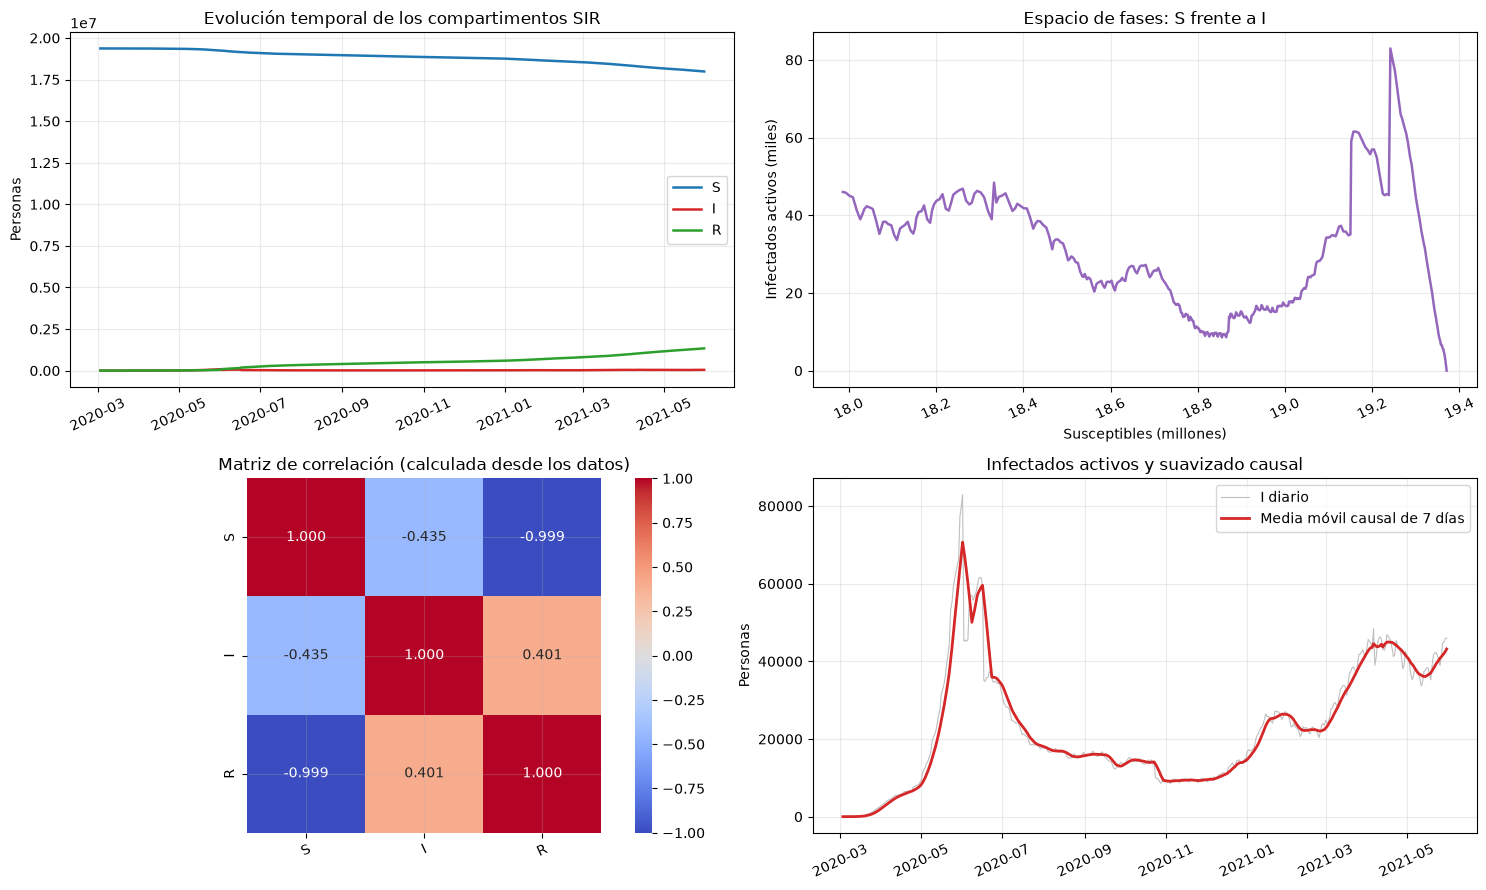

,S,I,R
S,1.000,-0.435,-0.999
I,-0.435,1.000,0.401
R,-0.999,0.401,1.000


In [107]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for col, color in zip(COMPARTMENTS, ["tab:blue", "tab:red", "tab:green"]):
    axes[0, 0].plot(df.index, df[col], label=col, color=color, linewidth=1.8)
axes[0, 0].set_title("Evolución temporal de los compartimentos SIR")
axes[0, 0].set_ylabel("Personas")
axes[0, 0].legend()

axes[0, 1].plot(df["S"] / 1e6, df["I"] / 1e3, color="tab:purple", linewidth=1.8)
axes[0, 1].set_title("Espacio de fases: S frente a I")
axes[0, 1].set_xlabel("Susceptibles (millones)")
axes[0, 1].set_ylabel("Infectados activos (miles)")

corr_matrix = df[COMPARTMENTS].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, ax=axes[1, 0])
axes[1, 0].set_title("Matriz de correlación (calculada desde los datos)")

axes[1, 1].plot(df.index, df["I"], color="0.75", linewidth=0.8, label="I diario")
axes[1, 1].plot(df.index, df["I"].rolling(7, min_periods=1).mean(),
                color="tab:red", linewidth=2, label="Media móvil causal de 7 días")
axes[1, 1].set_title("Infectados activos y suavizado causal")
axes[1, 1].set_ylabel("Personas")
axes[1, 1].legend()

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

display(corr_matrix.round(4))

## 4. Diseño experimental sin fuga temporal

### 4.1 Partición cronológica

El último 20 % de las observaciones se reserva para la evaluación fuera de muestra. La división respeta el orden temporal: los primeros datos se utilizan para entrenamiento y validación, mientras que el bloque final se mantiene separado hasta la evaluación de los pronósticos.

El escalado, la validación cruzada, la selección de hiperparámetros y el ajuste de los modelos se realizan exclusivamente con datos del período de entrenamiento.

### 4.2 Estimación de derivadas

Los conteos diarios pueden contener retrasos y revisiones administrativas. Para reducir parte de esta variabilidad, se aplica una media móvil retrospectiva de siete días (`center=False`), que utiliza únicamente observaciones pasadas y actuales.

Las derivadas se aproximan mediante diferencias finitas hacia adelante entre estados suavizados consecutivos:

$$
\dot{\mathbf{x}}_i \approx
\frac{\mathbf{x}_{i+1,\text{smooth}}-\mathbf{x}_{i,\text{smooth}}}
{t_{i+1}-t_i}.
$$

Cada ejemplo supervisado utiliza el estado inicial de una transición como entrada y la derivada aproximada durante el intervalo siguiente como objetivo. De esta manera, se construyen 363 transiciones a partir de los 364 estados suavizados del conjunto de entrenamiento.

Las transiciones se construyen exclusivamente dentro del período de entrenamiento. El bloque de prueba no participa en la estimación de derivadas ni en el ajuste de los modelos.

### 4.3 Validación y selección de hiperparámetros

Se utiliza validación cruzada cronológica mediante `TimeSeriesSplit`, con cinco particiones y una separación (`gap`) igual al tamaño de la ventana móvil. No se barajan las observaciones.

Los escaladores de entradas y objetivos se incorporan dentro de `Pipeline` y `TransformedTargetRegressor`, de modo que se ajustan independientemente dentro de cada partición de entrenamiento y se evita la fuga de información durante el preprocesamiento.

En la primera etapa, `GridSearchCV` evalúa por separado los modelos para las derivadas de infectados (\(dI/dt\)) y recuperados (\(dR/dt\)). Se utiliza el error cuadrático medio como criterio principal de selección (`neg_mean_squared_error`), mientras que \(R^2\) se conserva como métrica complementaria.

En una segunda etapa, los hiperparámetros se refinan mediante una búsqueda local por coordenadas basada en el error de las trayectorias integradas. Para ello, se simula cada partición de validación mediante Runge-Kutta de cuarto orden (RK4) y se calcula el RMSE normalizado de los compartimentos infectado y recuperado. Las trayectorias con valores negativos o errores no finitos se descartan.

Finalmente, los modelos seleccionados se reajustan utilizando todas las transiciones disponibles en el conjunto de entrenamiento.


In [130]:

# ============================================================
# 1. PREPARACIÓN DE DATOS Y PARTICIÓN CRONOLÓGICA
# ============================================================

dates = df.index
t = df["Day"].to_numpy(dtype=float)
X_raw = df[COMPARTMENTS].to_numpy(dtype=float)

# Verificar los compartimentos SIR
if set(COMPARTMENTS) != {"S", "I", "R"}:
    raise ValueError("COMPARTMENTS debe contener S, I y R.")

s_idx = COMPARTMENTS.index("S")
i_idx = COMPARTMENTS.index("I")
r_idx = COMPARTMENTS.index("R")

# Verificar el orden cronológico y la calidad de los datos
if not dates.is_monotonic_increasing or dates.has_duplicates:
    raise ValueError("Las fechas deben estar ordenadas y ser únicas.")

if not np.isfinite(t).all() or not np.isfinite(X_raw).all():
    raise ValueError("El conjunto de datos contiene valores no finitos.")

if np.any(X_raw < 0):
    raise ValueError("Los compartimentos SIR no pueden contener valores negativos.")

if np.any(np.diff(t) <= 0):
    raise ValueError("Los valores temporales deben ser estrictamente crecientes.")

# Verificar la conservación de la población en las observaciones originales
raw_mass_error = np.max(
    np.abs(X_raw.sum(axis=1) - POPULATION)
)

if raw_mass_error > 1e-5:
    raise ValueError(
        f"Los datos SIR originales no respetan la conservación de la población: "
        f"{raw_mass_error}"
    )

# División cronológica 80/20
split_idx = int(np.floor(len(df) * TRAIN_FRACTION))

if split_idx < 60 or (len(df) - split_idx) < 20:
    raise ValueError(
        "La partición dejó muy pocas observaciones para el entrenamiento o la prueba."
    )


# ============================================================
# 2. SUAVIZADO CAUSAL
# ============================================================

if ROLLING_WINDOW < 1:
    raise ValueError("ROLLING_WINDOW debe ser >= 1.")

X_smooth_all = (
    df[COMPARTMENTS]
    .rolling(
        window=ROLLING_WINDOW,
        min_periods=1,
        center=False
    )
    .mean()
    .to_numpy(dtype=float)
)

# La ventana móvil retrospectiva utiliza únicamente observaciones pasadas y actuales.
train_dates = dates[:split_idx]
test_dates = dates[split_idx:]

t_train = t[:split_idx]
t_test = t[split_idx:]

X_train_smooth = X_smooth_all[:split_idx]
X_test_smooth = X_smooth_all[split_idx:]

X_test_raw = X_raw[split_idx:]


# ============================================================
# 3. CONSTRUCCIÓN DE TRANSICIONES DE ESTADO HACIA ADELANTE
# ============================================================

# Estados iniciales x_i
X_train = X_train_smooth[:-1]

# Estados siguientes observados x_(i+1)
X_next_train = X_train_smooth[1:]

# Intervalos temporales reales
dt_train = np.diff(t_train)

if np.any(dt_train <= 0):
    raise ValueError("Los intervalos temporales de entrenamiento deben ser positivos.")

# Diferencias finitas hacia adelante:
# dX/dt = (x_(i+1) - x_i) / delta_t
dX_train = (
    X_next_train - X_train
) / dt_train[:, None]

if len(X_train) < 30:
    raise ValueError("No hay suficientes transiciones de entrenamiento.")

if not np.isfinite(dX_train).all():
    raise ValueError("Se detectaron valores no finitos en las derivadas.")


# ============================================================
# 4. ENTRADAS DEL ESTADO SIR COMPLETO
# ============================================================

# Utilizar el vector de estado completo como entrada:
# X = [S, I, R]
#
# Solo se ajustan dos derivadas independientes:
# dI/dt y dR/dt.
#
# La tercera derivada se reconstruye:
# dS/dt = -dI/dt - dR/dt.

X_train_model = X_train.copy()

dI_train = dX_train[:, i_idx]
dR_train = dX_train[:, r_idx]


# ============================================================
# 5. DIAGNÓSTICOS DE LOS DATOS Y DE CONSERVACIÓN
# ============================================================

print("=" * 55)
print("PARTICIÓN CRONOLÓGICA DE LOS DATOS")
print("=" * 55)

print(
    f"Entrenamiento: {train_dates[0].date()} a "
    f"{train_dates[-1].date()} "
    f"({len(train_dates)} observaciones)"
)

print(
    f"Prueba:       {test_dates[0].date()} a "
    f"{test_dates[-1].date()} "
    f"({len(test_dates)} observaciones)"
)

print("\nTransiciones de entrenamiento:", len(X_train_model))
print("Dimensiones de la entrada SIR completa:", X_train_model.shape)
print("Dimensiones del estado siguiente:", X_next_train.shape)

print("Dimensiones de la derivada de infectados:", dI_train.shape)
print("Dimensiones de la derivada de recuperados:", dR_train.shape)

print("\nIntervalos temporales:")
print("Mínimo:", dt_train.min())
print("Máximo:", dt_train.max())

print("\nError máximo de conservación de la población original:")
print(raw_mass_error)

print("\nError máximo de conservación de la población suavizada:")
print(
    np.max(
        np.abs(X_train_model.sum(axis=1) - POPULATION)
    )
)

print("\nError máximo de conservación de las derivadas:")
print(
    np.max(
        np.abs(dX_train.sum(axis=1))
    )
)

print("\nError máximo de reconstrucción de las transiciones:")
print(
    np.max(
        np.abs(
            X_train + dt_train[:, None] * dX_train
            - X_next_train
        )
    )
)

print("\nLas entradas del modelo utilizan S, I y R.")
print("El tiempo no se incluye como variable de entrada del modelo.")
print("La validación mantiene el orden cronológico; shuffle=False.")
print("=" * 55)

PARTICIÓN CRONOLÓGICA DE LOS DATOS
Entrenamiento: 2020-03-03 a 2021-03-01 (364 observaciones)
Prueba:       2021-03-02 a 2021-05-31 (91 observaciones)

Transiciones de entrenamiento: 363
Dimensiones de la entrada SIR completa: (363, 3)
Dimensiones del estado siguiente: (363, 3)
Dimensiones de la derivada de infectados: (363,)
Dimensiones de la derivada de recuperados: (363,)

Intervalos temporales:
Mínimo: 1.0
Máximo: 1.0

Error máximo de conservación de la población original:
0.0

Error máximo de conservación de la población suavizada:
3.725290298461914e-09

Error máximo de conservación de las derivadas:
3.245077095925808e-09

Error máximo de reconstrucción de las transiciones:
0.0

Las entradas del modelo utilizan S, I y R.
El tiempo no se incluye como variable de entrada del modelo.
La validación mantiene el orden cronológico; shuffle=False.


In [109]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

def make_scaled_regressor(base_estimator):
    """Scale X and y independently within each CV fold."""
    input_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", base_estimator),
    ])

    return TransformedTargetRegressor(
        regressor=input_pipeline,
        transformer=StandardScaler()
    )

In [131]:
# ============================================================
# 1. PREPROCESAMIENTO DE LOS MODELOS
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge


def make_scaled_regressor(base_estimator):
    """
    Escala las entradas y los objetivos de forma independiente
    dentro de cada partición de entrenamiento para evitar fugas
    de información durante el preprocesamiento.
    """
    input_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", base_estimator),
    ])

    return TransformedTargetRegressor(
        regressor=input_pipeline,
        transformer=StandardScaler()
    )


# Verificar que la nueva entrada contiene las tres variables
assert X_train_model.shape == (len(dI_train), 3)
assert X_train_model.shape == (len(dR_train), 3)


# ============================================================
# 2. VALIDACIÓN CRUZADA CRONOLÓGICA
# ============================================================

cv = TimeSeriesSplit(
    n_splits=5,
    gap=ROLLING_WINDOW
)

# El error cuadrático es el criterio principal de selección.
# R² se conserva como diagnóstico complementario.
scoring_metrics = {
    "neg_mse": "neg_mean_squared_error",
    "r2": "r2"
}


# ============================================================
# 3. GRILLAS DE HIPERPARÁMETROS
# ============================================================

ridge_grid = {
    "regressor__model__alpha": np.logspace(-4, 4, 17)
}

krr_grid = {
    "regressor__model__alpha": np.logspace(-4, 2, 13),
    "regressor__model__gamma": np.logspace(-3, 2, 15)
}


# ============================================================
# 4. RIDGE: DERIVADA DE LOS INFECTADOS
# ============================================================

ridge_I_search = GridSearchCV(
    estimator=make_scaled_regressor(Ridge()),
    param_grid=ridge_grid,
    cv=cv,
    scoring=scoring_metrics,
    refit="neg_mse",
    n_jobs=-1,
    error_score="raise"
)

ridge_I_search.fit(X_train_model, dI_train)


# ============================================================
# 5. RIDGE: DERIVADA DE LOS RECUPERADOS
# ============================================================

ridge_R_search = GridSearchCV(
    estimator=make_scaled_regressor(Ridge()),
    param_grid=ridge_grid,
    cv=cv,
    scoring=scoring_metrics,
    refit="neg_mse",
    n_jobs=-1,
    error_score="raise"
)

ridge_R_search.fit(X_train_model, dR_train)


# ============================================================
# 6. KRR: DERIVADA DE LOS INFECTADOS
# ============================================================

krr_I_search = GridSearchCV(
    estimator=make_scaled_regressor(
        KernelRidge(kernel="rbf")
    ),
    param_grid=krr_grid,
    cv=cv,
    scoring=scoring_metrics,
    refit="neg_mse",
    n_jobs=-1,
    error_score="raise"
)

krr_I_search.fit(X_train_model, dI_train)


# ============================================================
# 7. KRR: DERIVADA DE LOS RECUPERADOS
# ============================================================

krr_R_search = GridSearchCV(
    estimator=make_scaled_regressor(
        KernelRidge(kernel="rbf")
    ),
    param_grid=krr_grid,
    cv=cv,
    scoring=scoring_metrics,
    refit="neg_mse",
    n_jobs=-1,
    error_score="raise"
)

krr_R_search.fit(X_train_model, dR_train)


# ============================================================
# 8. ALMACENAMIENTO DE LOS MODELOS ÓPTIMOS
# ============================================================

best_ridge = {
    "I": ridge_I_search.best_estimator_,
    "R": ridge_R_search.best_estimator_
}

best_krr = {
    "I": krr_I_search.best_estimator_,
    "R": krr_R_search.best_estimator_
}


# ============================================================
# 9. RESUMEN DE LA VALIDACIÓN CRUZADA
# ============================================================

def summarize_search(model_name, target_name, search):

    idx = search.best_index_

    cv_mse = -search.cv_results_[
        "mean_test_neg_mse"
    ][idx]

    cv_r2 = search.cv_results_[
        "mean_test_r2"
    ][idx]

    return {
        "Modelo": model_name,
        "Objetivo": target_name,
        "Mejores parámetros": search.best_params_,
        "RMSE CV (personas/día)": np.sqrt(cv_mse),
        "R² CV": cv_r2
    }


cv_summary = pd.DataFrame([
    summarize_search("Ridge", "dI/dt", ridge_I_search),
    summarize_search("Ridge", "dR/dt", ridge_R_search),
    summarize_search("KRR RBF", "dI/dt", krr_I_search),
    summarize_search("KRR RBF", "dR/dt", krr_R_search)
])

display(cv_summary.round(4))


# ============================================================
# 10. VERIFICACIÓN DE LAS ENTRADAS DE LOS MODELOS
# ============================================================

print("\nVERIFICACIÓN DE LOS MODELOS")
print("Variables de entrada: S, I, R")
print("Número de características de entrada:", X_train_model.shape[1])
print("Observaciones de entrenamiento para infectados:", len(dI_train))
print("Observaciones de entrenamiento para recuperados:", len(dR_train))

print("\nHiperparámetros seleccionados para Ridge:")
print("Infectados:", ridge_I_search.best_params_)
print("Recuperados:", ridge_R_search.best_params_)

print("\nHiperparámetros seleccionados para KRR:")
print("Infectados:", krr_I_search.best_params_)
print("Recuperados:", krr_R_search.best_params_)

,Modelo,Objetivo,Mejores parámetros,RMSE CV (personas/día),R² CV
0,Ridge,dI/dt,{'regressor__model__alpha': 3162.2776601683795},"1,071.546",-0.690
1,Ridge,dR/dt,{'regressor__model__alpha': 1000.0},"2,192.583",-7.445
2,KRR RBF,dI/dt,"{'regressor__model__alpha': 10.0, 'regressor__...","1,055.422",-0.234
3,KRR RBF,dR/dt,"{'regressor__model__alpha': 0.1, 'regressor__m...","2,255.260",-2.603



VERIFICACIÓN DE LOS MODELOS
Variables de entrada: S, I, R
Número de características de entrada: 3
Observaciones de entrenamiento para infectados: 363
Observaciones de entrenamiento para recuperados: 363

Hiperparámetros seleccionados para Ridge:
Infectados: {'regressor__model__alpha': np.float64(3162.2776601683795)}
Recuperados: {'regressor__model__alpha': np.float64(1000.0)}

Hiperparámetros seleccionados para KRR:
Infectados: {'regressor__model__alpha': np.float64(10.0), 'regressor__model__gamma': np.float64(0.13894954943731375)}
Recuperados: {'regressor__model__alpha': np.float64(0.1), 'regressor__model__gamma': np.float64(0.0610540229658533)}


In [132]:
# ============================================================
# OPTIMIZACIÓN DE HIPERPARÁMETROS BASADA EN TRAYECTORIAS
# Entrada SIR completa: S, I, R
# Salidas independientes: dI/dt, dR/dt
# ============================================================

from sklearn.base import clone

# ------------------------------------------------------------
# 1. CONSTRUCCIÓN DEL MODELO
# ------------------------------------------------------------

def build_component_model(family, params):

    if family == "Ridge":
        estimator = Ridge(alpha=params["alpha"])

    elif family == "KRR":
        estimator = KernelRidge(
            kernel="rbf",
            alpha=params["alpha"],
            gamma=params["gamma"]
        )

    else:
        raise ValueError(f"Modelo desconocido: {family}")

    return make_scaled_regressor(estimator)


# ------------------------------------------------------------
# 2. VALIDACIÓN CRUZADA BASADA EN TRAYECTORIAS
# ------------------------------------------------------------

def trajectory_cv_score(family, params_I, params_R):

    fold_scores = []

    for train_idx, val_idx in cv.split(X_train_model):

        # Ajustar utilizando únicamente la porción de entrenamiento
        # de cada partición
        model_I = build_component_model(
            family, params_I
        )

        model_R = build_component_model(
            family, params_R
        )

        model_I.fit(
            X_train_model[train_idx],
            dI_train[train_idx]
        )

        model_R.fit(
            X_train_model[train_idx],
            dR_train[train_idx]
        )

        fold_models = {
            "I": model_I,
            "R": model_R
        }

        # Estado observado inicial del segmento de validación
        initial_state = X_train[val_idx[0]]

        # Incluir el punto final del período de validación
        fold_times = t_train[
            val_idx[0]:val_idx[-1] + 2
        ]

        # Integrar el estado SIR completo
        predicted_path = rk4_integrate(
            fold_models,
            initial_state,
            fold_times
        )

        predicted_states = predicted_path[1:]
        actual_states = X_next_train[val_idx]

        # Comparar los dos compartimentos independientes
        predicted_IR = predicted_states[:, [i_idx, r_idx]]
        actual_IR = actual_states[:, [i_idx, r_idx]]

        # Normalizar utilizando únicamente las observaciones
        # de entrenamiento de cada partición
        scale = np.std(
            X_train[train_idx][:, [i_idx, r_idx]],
            axis=0
        )

        scale = np.maximum(scale, 1e-8)

        normalized_error = (
            predicted_IR - actual_IR
        ) / scale

        fold_rmse = np.sqrt(
            np.mean(normalized_error ** 2)
        )

        # Rechazar trayectorias físicamente no admisibles
        if (
            not np.isfinite(fold_rmse)
            or np.any(predicted_states < -1e-6)
        ):
            return np.inf, []

        fold_scores.append(fold_rmse)

    return float(np.mean(fold_scores)), fold_scores


# ------------------------------------------------------------
# 3. CANDIDATOS LOCALES DE HIPERPARÁMETROS
# ------------------------------------------------------------

def local_candidates(family, center):

    factors = [0.5, 1.0, 2.0]

    if family == "Ridge":

        alpha_values = np.unique(np.clip(
            [center["alpha"] * f for f in factors],
            1e-4,
            1e4
        ))

        return [
            {"alpha": float(a)}
            for a in alpha_values
        ]

    alpha_values = np.unique(np.clip(
        [center["alpha"] * f for f in factors],
        1e-4,
        1e2
    ))

    gamma_values = np.unique(np.clip(
        [center["gamma"] * f for f in factors],
        1e-3,
        1e2
    ))

    return [
        {"alpha": float(a), "gamma": float(g)}
        for a in alpha_values
        for g in gamma_values
    ]


# ------------------------------------------------------------
# 4. BÚSQUEDA POR COORDENADAS
# ------------------------------------------------------------

def tune_by_trajectory(
    family,
    initial_I,
    initial_R,
    rounds=2
):

    params = {
        "I": initial_I.copy(),
        "R": initial_R.copy()
    }

    initial_score, initial_folds = trajectory_cv_score(
        family,
        params["I"],
        params["R"]
    )

    history = []

    for iteration in range(rounds):

        for component in ["I", "R"]:

            candidates = local_candidates(
                family,
                params[component]
            )

            candidate_results = []

            for candidate in candidates:

                trial_I = (
                    candidate if component == "I"
                    else params["I"]
                )

                trial_R = (
                    candidate if component == "R"
                    else params["R"]
                )

                score, _ = trajectory_cv_score(
                    family,
                    trial_I,
                    trial_R
                )

                candidate_results.append(
                    (score, candidate)
                )

            best_score, best_candidate = min(
                candidate_results,
                key=lambda item: item[0]
            )

            if not np.isfinite(best_score):
                raise RuntimeError(
                    f"No se encontró una trayectoria válida para {family}, {component}"
                )

            params[component] = best_candidate.copy()

            history.append({
                "Modelo": family,
                "Ronda": iteration + 1,
                "Componente": component,
                "RMSE CV de trayectoria": best_score,
                "Parámetros": best_candidate.copy()
            })

    final_score, final_folds = trajectory_cv_score(
        family,
        params["I"],
        params["R"]
    )

    return (
        params,
        initial_score,
        final_score,
        final_folds,
        history
    )


# ------------------------------------------------------------
# 5. HIPERPARÁMETROS INICIALES DE LA BÚSQUEDA EN GRILLA
# ------------------------------------------------------------

ridge_initial_I = {
    "alpha": float(
        ridge_I_search.best_params_["regressor__model__alpha"]
    )
}

ridge_initial_R = {
    "alpha": float(
        ridge_R_search.best_params_["regressor__model__alpha"]
    )
}

krr_initial_I = {
    "alpha": float(
        krr_I_search.best_params_["regressor__model__alpha"]
    ),
    "gamma": float(
        krr_I_search.best_params_["regressor__model__gamma"]
    )
}

krr_initial_R = {
    "alpha": float(
        krr_R_search.best_params_["regressor__model__alpha"]
    ),
    "gamma": float(
        krr_R_search.best_params_["regressor__model__gamma"]
    )
}


# ------------------------------------------------------------
# 6. OPTIMIZACIÓN DE AMBAS FAMILIAS DE MODELOS
# ------------------------------------------------------------

(
    ridge_params,
    ridge_start,
    ridge_final,
    ridge_folds,
    ridge_history
) = tune_by_trajectory(
    "Ridge",
    ridge_initial_I,
    ridge_initial_R
)

(
    krr_params,
    krr_start,
    krr_final,
    krr_folds,
    krr_history
) = tune_by_trajectory(
    "KRR",
    krr_initial_I,
    krr_initial_R
)


# ------------------------------------------------------------
# 7. REAJUSTE CON TODAS LAS TRANSICIONES DE ENTRENAMIENTO
# ------------------------------------------------------------

best_ridge = {
    "I": build_component_model(
        "Ridge", ridge_params["I"]
    ).fit(X_train_model, dI_train),

    "R": build_component_model(
        "Ridge", ridge_params["R"]
    ).fit(X_train_model, dR_train)
}

best_krr = {
    "I": build_component_model(
        "KRR", krr_params["I"]
    ).fit(X_train_model, dI_train),

    "R": build_component_model(
        "KRR", krr_params["R"]
    ).fit(X_train_model, dR_train)
}


# ------------------------------------------------------------
# 8. RESULTADOS
# ------------------------------------------------------------

trajectory_summary = pd.DataFrame([
    {
        "Modelo": "Ridge",
        "CV inicial": ridge_start,
        "CV final": ridge_final
    },
    {
        "Modelo": "KRR",
        "CV inicial": krr_start,
        "CV final": krr_final
    }
])

trajectory_history = pd.DataFrame(
    ridge_history + krr_history
)

display(trajectory_summary.round(4))

print("\nHiperparámetros seleccionados para Ridge:")
print(ridge_params)

print("\nHiperparámetros seleccionados para KRR:")
print(krr_params)

print("\nResultados por partición de Ridge:")
print(np.round(ridge_folds, 4))

print("\nResultados por partición de KRR:")
print(np.round(krr_folds, 4))


,Modelo,CV inicial,CV final
0,Ridge,9.127,8.600
1,KRR,9.265,9.065



Hiperparámetros seleccionados para Ridge:
{'I': {'alpha': 1581.1388300841897}, 'R': {'alpha': 250.0}}

Hiperparámetros seleccionados para KRR:
{'I': {'alpha': 2.5, 'gamma': 0.06947477471865687}, 'R': {'alpha': 0.05, 'gamma': 0.015263505741463325}}

Resultados por partición de Ridge:
[39.7745  2.3185  0.2113  0.1862  0.5079]

Resultados por partición de KRR:
[44.2615  0.4266  0.1659  0.0974  0.3722]


## 5. Integración numérica y restricciones del sistema

Los modelos Ridge y Kernel Ridge Regression aprenden dos componentes independientes del campo vectorial a partir del estado completo del sistema SIR:

$$
\dot I = f_I(S,I,R),
\qquad
\dot R = f_R(S,I,R).
$$

La derivada del compartimento susceptible se reconstruye algebraicamente mediante la condición de conservación poblacional:

$$
\dot S = -\dot I-\dot R.
$$

De esta manera, el campo vectorial satisface por construcción:

$$
\dot S+\dot I+\dot R=0.
$$

Por lo tanto, si el estado inicial cumple \(S+I+R=N\), la integración conserva la población total, salvo pequeños errores numéricos asociados a la precisión de punto flotante. Esta restricción se impone mediante la reconstrucción de la derivada de susceptibles, y no mediante una proyección posterior de las predicciones.

La integración numérica se realiza mediante el método clásico de Runge-Kutta de cuarto orden (RK4). El integrador utiliza subpasos dentro de cada intervalo de evaluación para mejorar la aproximación numérica de las trayectorias.

Los pronósticos comienzan en el último estado suavizado disponible del conjunto de entrenamiento. A partir de ese estado inicial, cada modelo se integra a lo largo del horizonte temporal reservado para prueba. El estado inicial se utiliza como condición de partida y no se incluye nuevamente entre los valores pronosticados.

No se recortan ni se fuerzan artificialmente a cero los estados negativos. La no negatividad de los compartimentos se evalúa como un diagnóstico independiente, ya que la aparición de valores negativos indicaría una trayectoria físicamente no admisible.


In [133]:
def project_conservation(derivative: np.ndarray) -> np.ndarray:
    """Proyecta [dS,dI,dR] para imponer dS+dI+dR=0."""
    derivative = np.asarray(derivative, dtype=float).reshape(3)
    return derivative - derivative.mean()



def vector_field(models, state):

    state = np.asarray(state, dtype=float).reshape(1, 3)

    dI = float(models["I"].predict(state)[0])
    dR = float(models["R"].predict(state)[0])

    dS = -dI - dR

    derivative = np.array([dS, dI, dR])

    if not np.isfinite(derivative).all():
        raise FloatingPointError("El modelo produjo una derivada no finita.")

    return derivative



def rk4_integrate(model, initial_state: np.ndarray, evaluation_times: np.ndarray,
                  substeps_per_day: int = RK4_SUBSTEPS_PER_DAY) -> np.ndarray:
    """Integra el campo vectorial aprendido mediante RK4 entre los tiempos de evaluación."""
    evaluation_times = np.asarray(evaluation_times, dtype=float)
    if evaluation_times.ndim != 1 or len(evaluation_times) < 1:
        raise ValueError("evaluation_times debe ser un vector no vacío.")
    if np.any(np.diff(evaluation_times) <= 0):
        raise ValueError("evaluation_times debe ser estrictamente creciente.")
    if substeps_per_day < 1:
        raise ValueError("substeps_per_day debe ser >= 1.")

    trajectory = np.empty((len(evaluation_times), 3), dtype=float)
    trajectory[0] = np.asarray(initial_state, dtype=float).reshape(3)

    for i in range(1, len(evaluation_times)):
        interval = evaluation_times[i] - evaluation_times[i - 1]
        n_steps = max(1, int(np.ceil(interval * substeps_per_day)))
        h = interval / n_steps
        state = trajectory[i - 1].copy()

        for _ in range(n_steps):
            k1 = vector_field(model, state)
            k2 = vector_field(model, state + 0.5 * h * k1)
            k3 = vector_field(model, state + 0.5 * h * k2)
            k4 = vector_field(model, state + h * k3)
            state = state + (h / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
            if not np.isfinite(state).all():
                raise FloatingPointError("La integración produjo un estado no finito.")

        trajectory[i] = state
    return trajectory




# ============================================================
# PRONÓSTICOS SIR FINALES: RIDGE Y KRR CON TRES VARIABLES DE ENTRADA
# ============================================================

forecast_times = t[split_idx - 1:]
initial_state = X_train_smooth[-1].copy()

# Integración del modelo Ridge
forecast_ridge_path = rk4_integrate(
    best_ridge,
    initial_state,
    forecast_times
)

# Integración del modelo KRR
forecast_krr_path = rk4_integrate(
    best_krr,
    initial_state,
    forecast_times
)

# Excluir el estado inicial correspondiente al último día de entrenamiento
forecast_ridge = forecast_ridge_path[1:]
forecast_krr = forecast_krr_path[1:]

# Modelo de persistencia como referencia
forecast_persistence = np.repeat(
    initial_state[None, :],
    len(test_dates),
    axis=0
)

# ============================================================
# VALIDACIÓN NUMÉRICA
# ============================================================

for name, path in {
    "Ridge": forecast_ridge,
    "KRR": forecast_krr
}.items():

    print(f"\n{name}")
    print("S, I, R finales:",
          np.round(path[-1]).astype(int))

    print("Valores mínimos de S, I, R:",
          np.round(path.min(axis=0)).astype(int))

    print("Error máximo de conservación:",
          np.max(np.abs(
              path.sum(axis=1) - POPULATION
          )))

    print("Valores negativos:", np.sum(path < -1e-6))

assert forecast_ridge.shape == X_test_smooth.shape
assert forecast_krr.shape == X_test_smooth.shape

print("\nHorizonte de pronóstico:", len(test_dates), "días")
print("Generación de pronósticos completada.")


Ridge
S, I, R finales: [18261847    18966  1089811]
Valores mínimos de S, I, R: [18261847    18966   797250]
Error máximo de conservación: 1.4901161193847656e-08
Valores negativos: 0

KRR
S, I, R finales: [18093625    40695  1236304]
Valores mínimos de S, I, R: [18093625    22970   797582]
Error máximo de conservación: 1.862645149230957e-08
Valores negativos: 0

Horizonte de pronóstico: 91 días
Generación de pronósticos completada.


## 6. Evaluación fuera de muestra

Se informan dos comparaciones:

- **Principal:** pronóstico frente a observaciones suavizadas causalmente con la misma ventana de siete días que se usó para estimar el campo.
- **Sensibilidad:** pronóstico frente a los conteos diarios sin suavizar. Esta métrica incluye más ruido administrativo y por eso se interpreta como evaluación más estricta.

Se calculan RMSE, MAE, \(R^2\) y WAPE por compartimento. También se incluye un pronóstico ingenuo de persistencia (mantener el último estado conocido), para comprobar si los modelos dinámicos aportan valor frente a una referencia sencilla.


In [ ]:
def metric_table(y_true: np.ndarray, y_pred: np.ndarray, model_name: str,
                 target_name: str) -> pd.DataFrame:
    rows = []
    for j, compartment in enumerate(COMPARTMENTS):
        true_j = y_true[:, j]
        pred_j = y_pred[:, j]
        rmse = np.sqrt(mean_squared_error(true_j, pred_j))
        mae = mean_absolute_error(true_j, pred_j)
        r2 = r2_score(true_j, pred_j)
        denominator = np.sum(np.abs(true_j))
        wape = 100.0 * np.sum(np.abs(true_j - pred_j)) / denominator if denominator else np.nan
        rows.append({
            "Objetivo": target_name,
            "Modelo": model_name,
            "Compartimento": compartment,
            "RMSE (personas)": rmse,
            "MAE (personas)": mae,
            "R²": r2,
            "WAPE (%)": wape,
        })
    return pd.DataFrame(rows)


forecasts = {
    "Ridge lineal": forecast_ridge,
    "KRR RBF": forecast_krr,
    "Persistencia": forecast_persistence,
}

metrics_smoothed = pd.concat([
    metric_table(X_test_smooth, prediction, name, "Serie suavizada causal")
    for name, prediction in forecasts.items()
], ignore_index=True)
metrics_raw = pd.concat([
    metric_table(X_test_raw, prediction, name, "Serie diaria sin suavizar")
    for name, prediction in forecasts.items()
], ignore_index=True)

print("Métricas principales: bloque de prueba suavizado")
display(metrics_smoothed.round(3))
print("Análisis de sensibilidad: bloque de prueba con datos diarios sin suavizar")
display(metrics_raw.round(3))


# ============================================================
# COMPARACIÓN DEL PICO FINAL DE INFECTADOS
# ============================================================

peak_results = []

for name, values in {
    "Observado": X_test_smooth[:, i_idx],
    "Ridge": forecast_ridge[:, i_idx],
    "KRR": forecast_krr[:, i_idx],
}.items():

    idx = int(np.argmax(values))

    peak_results.append({
        "Modelo": name,
        "Fecha del pico": test_dates[idx].strftime("%Y-%m-%d"),
        "Cantidad máxima de infectados": round(float(values[idx])),
        "Día del pico": idx + 1
    })

peak_table = pd.DataFrame(peak_results).set_index("Modelo")
display(peak_table)

observed_peak = X_test_smooth[:, i_idx].max()
observed_peak_day = int(np.argmax(X_test_smooth[:, i_idx]))

print("\nErrores en la predicción del pico:")

for name, prediction in {
    "Ridge": forecast_ridge[:, i_idx],
    "KRR": forecast_krr[:, i_idx]
}.items():

    predicted_peak = int(np.argmax(prediction))

    magnitude_error = (
        100 * (prediction[predicted_peak] - observed_peak)
        / observed_peak
    )

    timing_error = predicted_peak - observed_peak_day

    print(
        f"{name}: error de magnitud={magnitude_error:+.2f}%, "
        f"error temporal={timing_error:+d} días"
    )
    # ============================================================
# FORECAST SKILL SCORE RELATIVE TO PERSISTENCE
# ============================================================

skill_rows = []

datasets = {
    "Serie suavizada": X_test_smooth,
    "Serie diaria sin suavizar": X_test_raw
}

for dataset_name, y_true in datasets.items():

    for model_name, prediction in forecasts.items():

        for j, compartment in enumerate(COMPARTMENTS):

            actual = y_true[:, j]
            predicted = prediction[:, j]
            baseline = forecast_persistence[:, j]

            model_sse = np.sum((actual - predicted) ** 2)

            persistence_sse = np.sum(
                (actual - baseline) ** 2
            )

            skill = (
                1 - model_sse / persistence_sse
                if persistence_sse > 0
                else np.nan
            )

            skill_rows.append({
                "Serie": dataset_name,
                "Modelo": model_name,
                "Compartimento": compartment,
                "Skill vs. Persistencia": skill
            })

skill_table = pd.DataFrame(skill_rows)

print("\nPRONÓSTICO: SKILL SCORE RELATIVO A PERSISTENCIA")
display(
    skill_table.pivot_table(
        index=["Serie", "Compartimento"],
        columns="Modelo",
        values="Skill vs. Persistencia"
    ).round(4)
)

Métricas principales: bloque de prueba suavizado


,Objetivo,Modelo,Compartimento,RMSE (personas),MAE (personas),R²,WAPE (%)
0,Serie suavizada causal,Ridge lineal,S,"144,567.430","120,683.921",0.221,0.660
1,Serie suavizada causal,Ridge lineal,I,"18,261.751","17,117.414",-8.924,44.662
2,Serie suavizada causal,Ridge lineal,R,"128,195.502","103,566.506",0.364,9.904
3,Serie suavizada causal,KRR RBF,S,"61,878.395","53,407.406",0.857,0.292
4,Serie suavizada causal,KRR RBF,I,"8,322.129","6,709.162",-1.061,17.505
5,Serie suavizada causal,KRR RBF,R,"57,241.193","47,049.738",0.873,4.499
6,Serie suavizada causal,Persistencia,S,"313,340.524","267,101.283",-2.658,1.461
7,Serie suavizada causal,Persistencia,I,"16,592.506","15,546.936",-7.193,40.564
8,Serie suavizada causal,Persistencia,R,"298,560.357","251,554.347",-2.447,24.057


Análisis de sensibilidad: bloque de prueba con datos diarios sin suavizar


,Objetivo,Modelo,Compartimento,RMSE (personas),MAE (personas),R²,WAPE (%)
0,Serie diaria sin suavizar,Ridge lineal,S,"160,442.716","138,792.935",0.051,0.760
1,Serie diaria sin suavizar,Ridge lineal,I,"18,825.260","17,813.237",-10.425,45.649
2,Serie diaria sin suavizar,Ridge lineal,R,"143,320.734","120,979.698",0.219,11.380
3,Serie diaria sin suavizar,KRR RBF,S,"78,532.104","71,516.420",0.773,0.391
4,Serie diaria sin suavizar,KRR RBF,I,"9,018.321","7,402.475",-1.622,18.970
5,Serie diaria sin suavizar,KRR RBF,R,"72,988.602","64,434.530",0.797,6.061
6,Serie diaria sin suavizar,Persistencia,S,"329,365.449","285,210.297",-2.998,1.561
7,Serie diaria sin suavizar,Persistencia,I,"17,171.112","16,242.758",-8.505,41.624
8,Serie diaria sin suavizar,Persistencia,R,"314,065.274","268,967.538",-2.751,25.301


,Fecha del pico,Cantidad máxima de infectados,Día del pico
Modelo,,,
Observado,2021-04-17,44994,47
Ridge,2021-03-02,22761,1
KRR,2021-05-31,40695,91



Errores en la predicción del pico:
Ridge: error de magnitud=-49.41%, error temporal=-46 días
KRR: error de magnitud=-9.55%, error temporal=+44 días


In [135]:
print("HIPERPARÁMETROS FINALES DE RIDGE")
print("Infectados:", ridge_params["I"])
print("Recuperados:", ridge_params["R"])

print("\nHIPERPARÁMETROS FINALES DE KRR")
print("Infectados:", krr_params["I"])
print("Recuperados:", krr_params["R"])

print("\nCONFIGURACIÓN FINAL DEL ENTRENAMIENTO")
print("Variables de entrada:", COMPARTMENTS)
print("Observaciones de entrenamiento:", len(X_train_model))
print("Horizonte de pronóstico:", len(test_dates), "días")
print("Tamaño de la ventana móvil:", ROLLING_WINDOW)
print("Proporción de entrenamiento:", TRAIN_FRACTION)

HIPERPARÁMETROS FINALES DE RIDGE
Infectados: {'alpha': 1581.1388300841897}
Recuperados: {'alpha': 250.0}

HIPERPARÁMETROS FINALES DE KRR
Infectados: {'alpha': 2.5, 'gamma': 0.06947477471865687}
Recuperados: {'alpha': 0.05, 'gamma': 0.015263505741463325}

CONFIGURACIÓN FINAL DEL ENTRENAMIENTO
Variables de entrada: ['S', 'I', 'R']
Observaciones de entrenamiento: 363
Horizonte de pronóstico: 91 días
Tamaño de la ventana móvil: 7
Proporción de entrenamiento: 0.8


In [136]:
# Diagnóstico del pico de infectados dentro del periodo de prueba.
observed_peak_idx = int(np.argmax(X_test_smooth[:, 1]))
peak_rows = []
for model_name, prediction in forecasts.items():
    predicted_peak_idx = int(np.argmax(prediction[:, 1]))
    observed_peak = float(X_test_smooth[observed_peak_idx, 1])
    predicted_peak = float(prediction[predicted_peak_idx, 1])
    peak_rows.append({
        "Modelo": model_name,
        "Pico observado (personas)": observed_peak,
        "Fecha pico observado": test_dates[observed_peak_idx].date(),
        "Pico pronosticado (personas)": predicted_peak,
        "Fecha pico pronosticado": test_dates[predicted_peak_idx].date(),
        "Error magnitud (%)": 100.0 * (predicted_peak - observed_peak) / observed_peak
            if observed_peak else np.nan,
        "Error tiempo (días)": predicted_peak_idx - observed_peak_idx,
    })
peak_table = pd.DataFrame(peak_rows)
display(peak_table.round(2))

# Conservación, positividad y finitud para cada trayectoria integrada.
diagnostics = []
for model_name, path in [("Ridge lineal", forecast_ridge_path), ("KRR RBF", forecast_krr_path)]:
    mass_error = float(np.max(np.abs(path.sum(axis=1) - POPULATION)))
    diagnostics.append({
        "Modelo": model_name,
        "Error máximo de conservación (personas)": mass_error,
        "Mínimo S": float(path[:, 0].min()),
        "Mínimo I": float(path[:, 1].min()),
        "Mínimo R": float(path[:, 2].min()),
        "¿Todos los estados no negativos?": bool((path >= 0).all()),
        "¿Todos los estados finitos?": bool(np.isfinite(path).all()),
    })
diagnostics_table = pd.DataFrame(diagnostics)
display(diagnostics_table)

print("La conservación se impone en el campo vectorial; la positividad se comprueba, no se fuerza por recorte.")

,Modelo,Pico observado (personas),Fecha pico observado,Pico pronosticado (personas),Fecha pico pronosticado,Error magnitud (%),Error tiempo (días)
0,Ridge lineal,"44,993.710",2021-04-17,"22,761.170",2021-03-02,-49.410,-46
1,KRR RBF,"44,993.710",2021-04-17,"40,695.170",2021-05-31,-9.550,44
2,Persistencia,"44,993.710",2021-04-17,"22,779.710",2021-03-02,-49.370,-46


,Modelo,Error máximo de conservación (personas),Mínimo S,Mínimo I,Mínimo R,¿Todos los estados no negativos?,¿Todos los estados finitos?
0,Ridge lineal,0.000,"18,261,846.779","18,965.898","794,116.714",True,True
1,KRR RBF,0.000,"18,093,624.943","22,779.714","794,116.714",True,True


La conservación se impone en el campo vectorial; la positividad se comprueba, no se fuerza por recorte.


## 7. Gráficos del pronóstico reservado

La línea vertical marca el corte entre entrenamiento y prueba. El segmento de pronóstico empieza en el último día de entrenamiento; las métricas se calculan exclusivamente después de ese corte. Se visualizan también los datos diarios originales para no ocultar la variabilidad de los reportes.

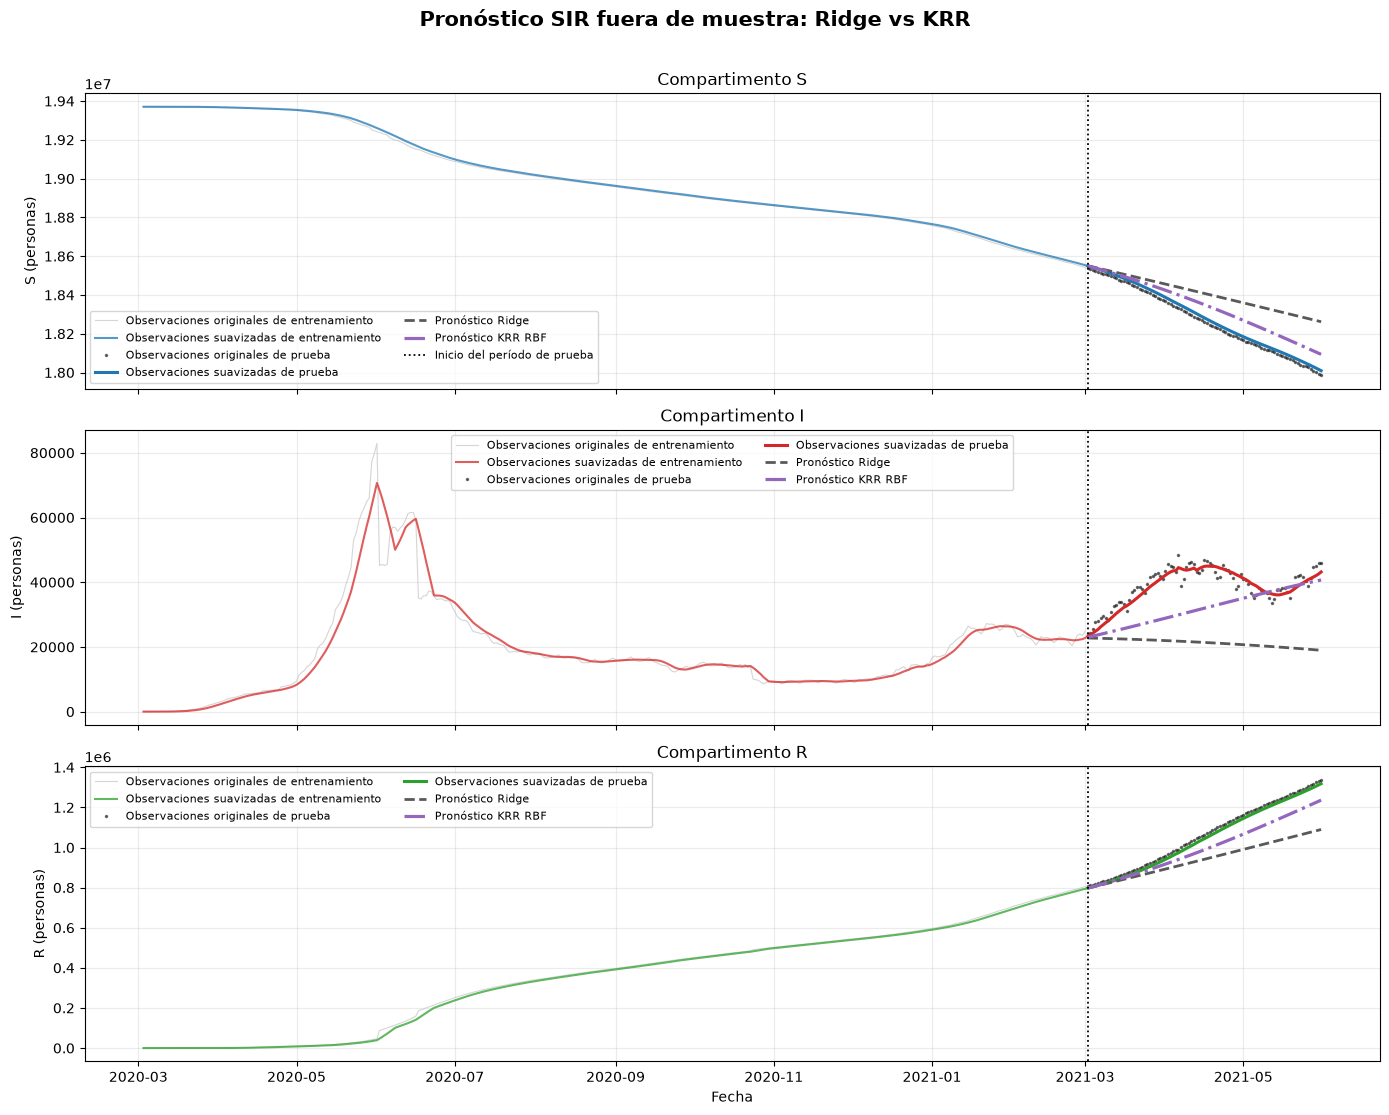

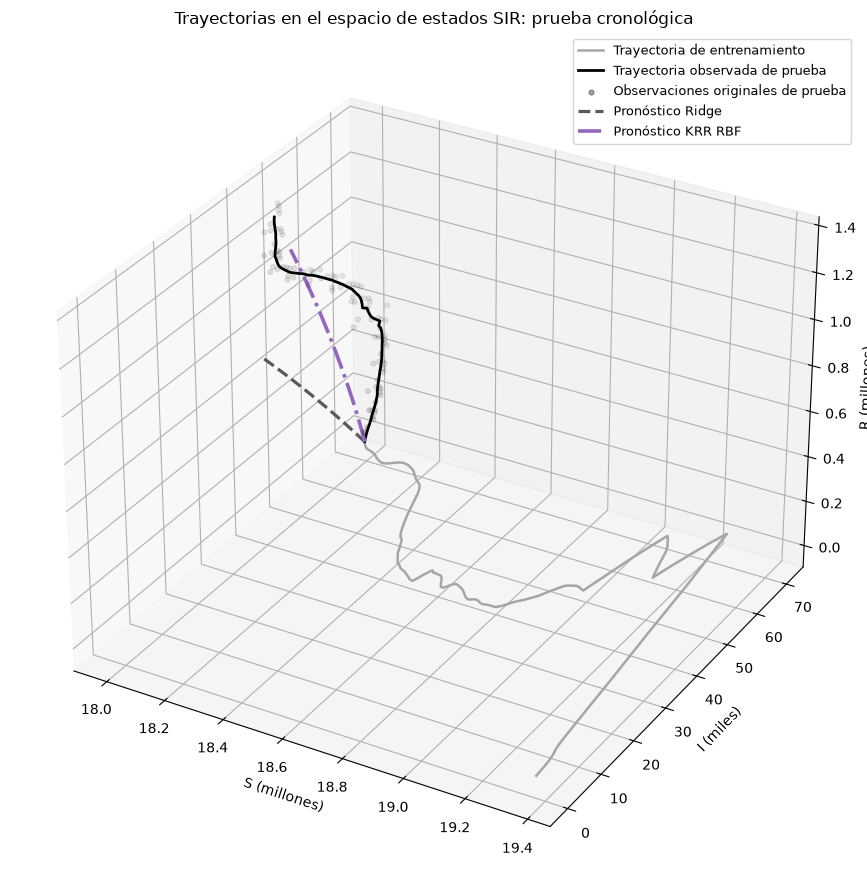


COMPARACIÓN DEL PICO DE INFECTADOS


,Fecha del pico,Cantidad de infectados en el pico,Día del pico,Error de magnitud (%),Error temporal (días)
Modelo,,,,,
Observado,2021-04-17,44994,47,0.000,0
Ridge,2021-03-02,22761,1,-49.410,-46
KRR RBF,2021-05-31,40695,91,-9.550,44



RESUMEN FINAL DEL PRONÓSTICO DE INFECTADOS


,Infectados iniciales,Infectados finales,Mínimo de infectados,Máximo de infectados,MAE de infectados,RMSE de infectados,R² de infectados
Modelo,,,,,,,
Ridge,22761,18966,18966,22761,"17,117.414","18,261.751",-8.924
KRR RBF,22970,40695,22970,40695,"6,709.162","8,322.129",-1.061


In [137]:

# ============================================================
# VISUALIZACIÓN FINAL DE LOS PRONÓSTICOS SIR FUERA DE MUESTRA
# Ridge vs KRR
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. VERIFICACIÓN DE LOS PRONÓSTICOS FINALES
# ------------------------------------------------------------

assert forecast_ridge.shape == X_test_smooth.shape
assert forecast_krr.shape == X_test_smooth.shape

assert np.isfinite(forecast_ridge).all()
assert np.isfinite(forecast_krr).all()

# Identificar las posiciones de los compartimentos
s_idx = COMPARTMENTS.index("S")
i_idx = COMPARTMENTS.index("I")
r_idx = COMPARTMENTS.index("R")

# Colores consistentes para cada compartimento
compartment_colors = {
    "S": "tab:blue",
    "I": "tab:red",
    "R": "tab:green"
}

model_colors = {
    "Ridge": "0.35",
    "KRR RBF": "tab:purple"
}


# ============================================================
# 2. PRONÓSTICO TEMPORAL EN TRES GRÁFICOS
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11),
    sharex=True
)

for j, compartment in enumerate(COMPARTMENTS):

    ax = axes[j]
    color = compartment_colors[compartment]

    # Observaciones originales del entrenamiento
    ax.plot(
        train_dates,
        X_raw[:split_idx, j],
        color="0.75",
        linewidth=0.8,
        alpha=0.65,
        label="Observaciones originales de entrenamiento"
    )

    # Trayectoria suavizada utilizada durante el ajuste
    ax.plot(
        train_dates,
        X_train_smooth[:, j],
        color=color,
        linewidth=1.5,
        alpha=0.75,
        label="Observaciones suavizadas de entrenamiento"
    )

    # Observaciones originales del bloque de prueba
    ax.plot(
        test_dates,
        X_test_raw[:, j],
        color="black",
        marker=".",
        linestyle="none",
        markersize=3,
        alpha=0.5,
        label="Observaciones originales de prueba"
    )

    # Observaciones suavizadas del bloque de prueba
    # (objetivo principal de evaluación)
    ax.plot(
        test_dates,
        X_test_smooth[:, j],
        color=color,
        linewidth=2.2,
        linestyle="-",
        label="Observaciones suavizadas de prueba"
    )

    # Pronóstico Ridge
    ax.plot(
        test_dates,
        forecast_ridge[:, j],
        color=model_colors["Ridge"],
        linestyle="--",
        linewidth=2.0,
        label="Pronóstico Ridge"
    )

    # Pronóstico KRR
    ax.plot(
        test_dates,
        forecast_krr[:, j],
        color=model_colors["KRR RBF"],
        linestyle="-.",
        linewidth=2.3,
        label="Pronóstico KRR RBF"
    )

    # Límite entre los períodos de entrenamiento y prueba
    ax.axvline(
        test_dates[0],
        color="black",
        linestyle=":",
        linewidth=1.3,
        label="Inicio del período de prueba" if j == 0 else None
    )

    ax.set_ylabel(f"{compartment} (personas)")
    ax.set_title(f"Compartimento {compartment}")
    ax.grid(True, alpha=0.25)
    ax.legend(
        loc="best",
        fontsize=8,
        ncols=2
    )

axes[-1].set_xlabel("Fecha")

fig.suptitle(
    "Pronóstico SIR fuera de muestra: Ridge vs KRR",
    fontsize=15,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()


# ============================================================
# 3. ESPACIO DE FASES SIR TRIDIMENSIONAL
# ============================================================

# Conectar el pronóstico con la última observación del entrenamiento
initial_state = X_train_smooth[-1]

ridge_phase = np.vstack([
    initial_state,
    forecast_ridge
])

krr_phase = np.vstack([
    initial_state,
    forecast_krr
])

actual_test_phase = np.vstack([
    initial_state,
    X_test_smooth
])

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Trayectoria de entrenamiento
ax.plot(
    X_train_smooth[:, s_idx] / 1e6,
    X_train_smooth[:, i_idx] / 1e3,
    X_train_smooth[:, r_idx] / 1e6,
    color="0.65",
    linewidth=1.8,
    label="Trayectoria de entrenamiento"
)

# Trayectoria observada del período de prueba
ax.plot(
    actual_test_phase[:, s_idx] / 1e6,
    actual_test_phase[:, i_idx] / 1e3,
    actual_test_phase[:, r_idx] / 1e6,
    color="black",
    linewidth=2.0,
    label="Trayectoria observada de prueba"
)

# Observaciones originales del período de prueba
ax.scatter(
    X_test_raw[:, s_idx] / 1e6,
    X_test_raw[:, i_idx] / 1e3,
    X_test_raw[:, r_idx] / 1e6,
    color="black",
    s=12,
    alpha=0.35,
    label="Observaciones originales de prueba"
)

# Trayectoria pronosticada por Ridge
ax.plot(
    ridge_phase[:, s_idx] / 1e6,
    ridge_phase[:, i_idx] / 1e3,
    ridge_phase[:, r_idx] / 1e6,
    color=model_colors["Ridge"],
    linestyle="--",
    linewidth=2.3,
    label="Pronóstico Ridge"
)

# Trayectoria pronosticada por KRR
ax.plot(
    krr_phase[:, s_idx] / 1e6,
    krr_phase[:, i_idx] / 1e3,
    krr_phase[:, r_idx] / 1e6,
    color=model_colors["KRR RBF"],
    linestyle="-.",
    linewidth=2.6,
    label="Pronóstico KRR RBF"
)

ax.set_xlabel("S (millones)")
ax.set_ylabel("I (miles)")
ax.set_zlabel("R (millones)")

ax.set_title(
    "Trayectorias en el espacio de estados SIR: prueba cronológica"
)

ax.legend(loc="best", fontsize=9)

plt.tight_layout()
plt.show()


# ============================================================
# 4. COMPARACIÓN NUMÉRICA DEL PICO DE INFECTADOS
# ============================================================

actual_infected = X_test_smooth[:, i_idx]

predictions_infected = {
    "Observado": actual_infected,
    "Ridge": forecast_ridge[:, i_idx],
    "KRR RBF": forecast_krr[:, i_idx]
}

observed_peak_idx = int(np.argmax(actual_infected))
observed_peak_value = float(actual_infected[observed_peak_idx])

peak_rows = []

for name, values in predictions_infected.items():

    peak_idx = int(np.argmax(values))
    peak_value = float(values[peak_idx])

    row = {
        "Modelo": name,
        "Fecha del pico": pd.Timestamp(
            test_dates[peak_idx]
        ).strftime("%Y-%m-%d"),
        "Cantidad de infectados en el pico": round(peak_value),
        "Día del pico": peak_idx + 1
    }

    if name != "Observado":

        row["Error de magnitud (%)"] = (
            100 * (peak_value - observed_peak_value)
            / observed_peak_value
        )

        row["Error temporal (días)"] = (
            peak_idx - observed_peak_idx
        )

    else:
        row["Error de magnitud (%)"] = 0.0
        row["Error temporal (días)"] = 0

    peak_rows.append(row)

peak_summary = pd.DataFrame(peak_rows).set_index("Modelo")

print("\nCOMPARACIÓN DEL PICO DE INFECTADOS")
display(peak_summary.round(2))


# ============================================================
# 5. RESUMEN NUMÉRICO FINAL DEL PRONÓSTICO
# ============================================================

summary_rows = []

for name, prediction in {
    "Ridge": forecast_ridge,
    "KRR RBF": forecast_krr
}.items():

    infected_prediction = prediction[:, i_idx]

    summary_rows.append({
        "Modelo": name,
        "Infectados iniciales": round(
            float(infected_prediction[0])
        ),
        "Infectados finales": round(
            float(infected_prediction[-1])
        ),
        "Mínimo de infectados": round(
            float(infected_prediction.min())
        ),
        "Máximo de infectados": round(
            float(infected_prediction.max())
        ),
        "MAE de infectados": mean_absolute_error(
            actual_infected,
            infected_prediction
        ),
        "RMSE de infectados": np.sqrt(
            mean_squared_error(
                actual_infected,
                infected_prediction
            )
        ),
        "R² de infectados": r2_score(
            actual_infected,
            infected_prediction
        )
    })

print("\nRESUMEN FINAL DEL PRONÓSTICO DE INFECTADOS")

display(
    pd.DataFrame(summary_rows)
    .set_index("Modelo")
    .round(3)
)

In [140]:
# ============================================================
# RESUMEN AUTOMÁTICO PARA LOS RESULTADOS Y LA DISCUSIÓN
# ============================================================

# ------------------------------------------------------------
# 1. COMPARACIÓN DEL RMSE POR COMPARTIMENTO
# ------------------------------------------------------------

summary = metrics_smoothed.pivot(
    index="Compartimento",
    columns="Modelo",
    values="RMSE (personas)"
)

print("RMSE por compartimento (un valor menor indica un mejor resultado):")
display(summary.round(2))

print("\nMejor modelo por compartimento:")

for compartment in COMPARTMENTS:

    ranked = (
        metrics_smoothed[
            metrics_smoothed["Compartimento"] == compartment
        ]
        .sort_values("RMSE (personas)")
    )

    best = ranked.iloc[0]

    print(
        f"{compartment}: {best['Modelo']} "
        f"(RMSE = {best['RMSE (personas)']:,.2f})"
    )


## ------------------------------------------------------------
# 2. PRECISIÓN EN LA ESTIMACIÓN DEL PICO DE INFECTADOS
# ------------------------------------------------------------

# Excluir la fila de referencia observada.
# Comparar únicamente los modelos de pronóstico.
predicted_peaks = peak_summary.drop(
    index="Observado",
    errors="ignore"
)

# Seleccionar el modelo con el menor error absoluto en la magnitud del pico.
best_by_peak = predicted_peaks.loc[
    predicted_peaks["Error de magnitud (%)"].abs().idxmin()
]

print("\nCOMPARACIÓN DEL PICO DE INFECTADOS")

print(
    "Menor error en la magnitud del pico:",
    best_by_peak.name
)

print(
    f"Error de magnitud: "
    f"{best_by_peak['Error de magnitud (%)']:+.2f}%"
)

print(
    f"Error temporal: "
    f"{best_by_peak['Error temporal (días)']:+.0f} días"
)
# ------------------------------------------------------------
# 3. INTERPRETACIÓN AUTOMÁTICA
# ------------------------------------------------------------

print("\nINTERPRETACIÓN FINAL")

for compartment in COMPARTMENTS:

    ranked = (
        metrics_smoothed[
            metrics_smoothed["Compartimento"] == compartment
        ]
        .sort_values("RMSE (personas)")
    )

    print(
        f"Para el compartimento {compartment}, "
        f"{ranked.iloc[0]['Modelo']} obtuvo el menor RMSE en el conjunto de prueba."
    )

print(
    f"En cuanto a la magnitud del pico de infectados, {best_by_peak.name} "
    f"presentó el menor error relativo."
)

RMSE por compartimento (un valor menor indica un mejor resultado):


Modelo,KRR RBF,Persistencia,Ridge lineal
Compartimento,,,
I,"8,322.130","16,592.510","18,261.750"
R,"57,241.190","298,560.360","128,195.500"
S,"61,878.390","313,340.520","144,567.430"



Mejor modelo por compartimento:
S: KRR RBF (RMSE = 61,878.39)
I: KRR RBF (RMSE = 8,322.13)
R: KRR RBF (RMSE = 57,241.19)

COMPARACIÓN DEL PICO DE INFECTADOS
Menor error en la magnitud del pico: KRR RBF
Error de magnitud: -9.55%
Error temporal: +44 días

INTERPRETACIÓN FINAL
Para el compartimento S, KRR RBF obtuvo el menor RMSE en el conjunto de prueba.
Para el compartimento I, KRR RBF obtuvo el menor RMSE en el conjunto de prueba.
Para el compartimento R, KRR RBF obtuvo el menor RMSE en el conjunto de prueba.
En cuanto a la magnitud del pico de infectados, KRR RBF presentó el menor error relativo.


## 8. Interpretación de resultados

Esta sección no contiene valores numéricos fijos, ya que las tablas y métricas presentadas anteriormente se actualizan al ejecutar el notebook. Para interpretar correctamente los resultados, es importante considerar los siguientes aspectos:

1. **Comparación con el modelo de persistencia.** El desempeño de Ridge y KRR debe evaluarse frente al modelo de referencia de Persistencia, y no únicamente comparando ambos modelos entre sí. Este modelo supone que el estado inicial del período de prueba se mantiene constante durante todo el horizonte de pronóstico.

2. **Evaluación por compartimento.** Los resultados del conjunto de prueba deben analizarse por separado para los compartimentos susceptible (S), infectado (I) y recuperado (R). Las métricas obtenidas indican que KRR presenta el menor RMSE en los tres compartimentos, tanto para las series suavizadas como para las observaciones diarias sin suavizar. Ridge también mejora respecto a Persistencia en los compartimentos susceptible y recuperado, aunque su desempeño en el compartimento infectado es inferior al de este modelo de referencia.

3. **Interpretación de R².** El coeficiente R² debe interpretarse con precaución, especialmente para el compartimento infectado. Un valor negativo indica que el modelo presenta un error cuadrático superior al de un predictor que utiliza la media observada del conjunto de prueba. Sin embargo, esto no implica necesariamente que el modelo sea peor que Persistencia, ya que ambos criterios utilizan referencias diferentes. Por ello, R² debe analizarse junto con RMSE y MAE.

4. **Estimación del pico de infectados.** Es necesario examinar tanto el error en la magnitud como el error temporal del pico. Los resultados muestran que una estimación relativamente precisa de la magnitud no garantiza una buena estimación del momento en que ocurre el máximo. En particular, el máximo pronosticado por KRR aparece al final del horizonte evaluado, mientras que el máximo observado ocurre antes. Por lo tanto, el máximo pronosticado debe interpretarse como el máximo dentro del período de prueba y no como una estimación confirmada del pico epidémico definitivo.

5. **Conservación y positividad.** La conservación de la población total se impone algebraicamente mediante la reconstrucción de la derivada del compartimento susceptible. Su cumplimiento debe verificarse numéricamente durante la integración. Asimismo, todos los compartimentos deben permanecer no negativos; la aparición de valores negativos indicaría una trayectoria físicamente inconsistente.

6. **Sensibilidad al suavizado.** La comparación entre las métricas de las series suavizadas y las series diarias originales permite evaluar la sensibilidad de los modelos al ruido de reporte. Aunque el desempeño general de KRR se mantiene en ambas evaluaciones, los errores tienden a ser mayores al utilizar las observaciones sin suavizar.

### 8.1 Limitaciones científicas

- Los datos de recuperados de JHU corresponden a una serie histórica de vigilancia epidemiológica, sujeta a cambios en la cobertura y en los criterios de notificación. Por lo tanto, la expresión `I = Confirmados - Recuperados - Fallecidos` constituye una aproximación contable y no necesariamente representa el número real de personas infecciosas en cada fecha.

- La identidad \(S+I+R=N\) constituye una restricción algebraica impuesta durante el preprocesamiento y reforzada en la reconstrucción del campo vectorial. Su cumplimiento no demuestra que la dinámica aprendida corresponda a un modelo SIR mecanístico.

- El campo vectorial aprendido es autónomo: supone que un mismo estado del sistema produce siempre las mismas derivadas. En una epidemia real, la transmisión puede variar debido a intervenciones sanitarias, cambios de comportamiento, vacunación, variantes y otros factores que no están representados explícitamente en el modelo.

- Las diferencias finitas y el suavizado causal ayudan a reducir el impacto del ruido en los datos diarios, pero no eliminan los errores de medición, las revisiones administrativas ni las inconsistencias en los reportes.

- La población se considera constante durante todo el período de estudio. El crecimiento demográfico se omite porque su efecto se considera pequeño en comparación con las variaciones observadas en las series analizadas.

- Los pronósticos son extrapolaciones deterministas del campo vectorial aprendido. No se estiman intervalos de incertidumbre ni se incorporan variables externas que permitan representar explícitamente cambios en las condiciones epidemiológicas.

## 9. Exportación de figuras

Las figuras exportadas se guardan en `docs/img/`, manteniendo las rutas usadas por el sitio del proyecto. Se exportan gráficos recalculados con la partición y los resultados actuales.

In [141]:

# ============================================================
# EXPORTACIÓN FINAL DE FIGURAS
# Ridge vs KRR — Modelo SIR de aprendizaje automático
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Directorio de salida
OUTPUT_DIR = Path("docs/img")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Colores consistentes para cada compartimento
compartment_colors = {
    "S": "tab:blue",
    "I": "tab:red",
    "R": "tab:green"
}

model_colors = {
    "Ridge": "0.35",
    "KRR": "tab:purple"
}

# Índices de los compartimentos
s_idx = COMPARTMENTS.index("S")
i_idx = COMPARTMENTS.index("I")
r_idx = COMPARTMENTS.index("R")

# Verificar los pronósticos antes de exportar
assert forecast_ridge.shape == X_test_smooth.shape
assert forecast_krr.shape == X_test_smooth.shape

assert np.isfinite(forecast_ridge).all()
assert np.isfinite(forecast_krr).all()


# ============================================================
# 1. ANÁLISIS EXPLORATORIO DE DATOS (EDA)
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

# Evolución temporal del sistema SIR
for compartment in COMPARTMENTS:
    axes[0].plot(
        df.index,
        df[compartment],
        label=compartment,
        color=compartment_colors[compartment],
        linewidth=1.6
    )

axes[0].set_title("Evolución de la población del sistema SIR")
axes[0].set_xlabel("Fecha")
axes[0].set_ylabel("Población (personas)")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(alpha=0.25)

# Matriz de correlación del sistema SIR
corr_matrix = df[COMPARTMENTS].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[1],
    cbar_kws={"shrink": 0.8}
)

axes[1].set_title("Matriz de correlación del sistema SIR")

# Representación del espacio de fases S-I
axes[2].plot(
    df["S"] / 1e6,
    df["I"] / 1e3,
    color="tab:purple",
    linewidth=1.5
)

axes[2].set_title("Espacio de fases S-I")
axes[2].set_xlabel("S (millones)")
axes[2].set_ylabel("I (miles)")
axes[2].grid(alpha=0.25)

fig.suptitle(
    "Análisis exploratorio de datos del sistema SIR",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "eda_sir.png",
    dpi=220,
    bbox_inches="tight"
)

plt.close(fig)


# ============================================================
# 2. PRONÓSTICOS FUERA DE MUESTRA (TRES COMPARTIMENTOS)
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11),
    sharex=True
)

for j, compartment in enumerate(COMPARTMENTS):

    ax = axes[j]
    color = compartment_colors[compartment]

    # Observaciones originales del conjunto de entrenamiento
    ax.plot(
        train_dates,
        X_raw[:split_idx, j],
        color="0.75",
        linewidth=0.8,
        alpha=0.65,
        label="Observaciones originales de entrenamiento"
    )

    # Observaciones suavizadas del conjunto de entrenamiento
    ax.plot(
        train_dates,
        X_train_smooth[:, j],
        color=color,
        linewidth=1.4,
        alpha=0.7,
        label="Observaciones suavizadas de entrenamiento"
    )

    # Observaciones originales del conjunto de prueba
    ax.plot(
        test_dates,
        X_test_raw[:, j],
        color="black",
        marker=".",
        linestyle="none",
        markersize=3,
        alpha=0.5,
        label="Observaciones originales de prueba"
    )

    # Observaciones suavizadas del conjunto de prueba
    ax.plot(
        test_dates,
        X_test_smooth[:, j],
        color=color,
        linewidth=2,
        label="Observaciones suavizadas de prueba"
    )

    # Pronóstico de Ridge
    ax.plot(
        test_dates,
        forecast_ridge[:, j],
        linestyle="--",
        color=model_colors["Ridge"],
        linewidth=2,
        label="Pronóstico de Ridge"
    )

    # Pronóstico de KRR
    ax.plot(
        test_dates,
        forecast_krr[:, j],
        linestyle="-.",
        color=model_colors["KRR"],
        linewidth=2.3,
        label="Pronóstico de KRR RBF"
    )

    # Límite entre los conjuntos de entrenamiento y prueba
    ax.axvline(
        test_dates[0],
        color="black",
        linestyle=":",
        linewidth=1.3,
        label="Inicio del período de prueba" if j == 0 else None
    )

    ax.set_title(f"Compartimento {compartment}")
    ax.set_ylabel(f"{compartment} (personas)")
    ax.legend(
        loc="best",
        fontsize=8,
        ncols=2
    )
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Fecha")

fig.suptitle(
    "Pronóstico SIR fuera de muestra: Ridge vs KRR",
    fontsize=14,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "resultados_2d.png",
    dpi=220,
    bbox_inches="tight"
)

plt.close(fig)


# ============================================================
# 3. ESPACIO DE FASES SIR EN TRES DIMENSIONES
# ============================================================

# Conectar el último estado del entrenamiento con las trayectorias de prueba
initial_state = X_train_smooth[-1]

actual_test_path = np.vstack([
    initial_state,
    X_test_smooth
])

ridge_test_path = np.vstack([
    initial_state,
    forecast_ridge
])

krr_test_path = np.vstack([
    initial_state,
    forecast_krr
])

fig = plt.figure(figsize=(11, 9))

ax = fig.add_subplot(
    111,
    projection="3d"
)

# Trayectoria suavizada del conjunto de entrenamiento
ax.plot(
    X_train_smooth[:, s_idx] / 1e6,
    X_train_smooth[:, i_idx] / 1e3,
    X_train_smooth[:, r_idx] / 1e6,
    color="0.65",
    linewidth=1.8,
    label="Trayectoria de entrenamiento"
)

# Trayectoria observada del conjunto de prueba
ax.plot(
    actual_test_path[:, s_idx] / 1e6,
    actual_test_path[:, i_idx] / 1e3,
    actual_test_path[:, r_idx] / 1e6,
    color="black",
    linewidth=2,
    label="Trayectoria observada de prueba"
)

# Observaciones originales del conjunto de prueba
ax.scatter(
    X_test_raw[:, s_idx] / 1e6,
    X_test_raw[:, i_idx] / 1e3,
    X_test_raw[:, r_idx] / 1e6,
    color="black",
    s=12,
    alpha=0.35,
    label="Observaciones originales de prueba"
)

# Trayectoria pronosticada por Ridge
ax.plot(
    ridge_test_path[:, s_idx] / 1e6,
    ridge_test_path[:, i_idx] / 1e3,
    ridge_test_path[:, r_idx] / 1e6,
    color=model_colors["Ridge"],
    linestyle="--",
    linewidth=2.3,
    label="Pronóstico de Ridge"
)

# Trayectoria pronosticada por KRR
ax.plot(
    krr_test_path[:, s_idx] / 1e6,
    krr_test_path[:, i_idx] / 1e3,
    krr_test_path[:, r_idx] / 1e6,
    color=model_colors["KRR"],
    linestyle="-.",
    linewidth=2.5,
    label="Pronóstico de KRR RBF"
)

ax.set_xlabel("S (millones)")
ax.set_ylabel("I (miles)")
ax.set_zlabel("R (millones)")

ax.set_title(
    "Trayectorias en el espacio de estados SIR: conjunto de prueba cronológico"
)

ax.legend(
    loc="best",
    fontsize=8
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "resultados_3d.png",
    dpi=220,
    bbox_inches="tight"
)

plt.close(fig)


# ============================================================
# 4. CONFIRMACIÓN DE LA EXPORTACIÓN
# ============================================================

print("=" * 55)
print("EXPORTACIÓN DE FIGURAS COMPLETADA")
print("=" * 55)

for filename in [
    "eda_sir.png",
    "resultados_2d.png",
    "resultados_3d.png"
]:

    filepath = OUTPUT_DIR / filename

    print(
        f"{filename}: "
        f"{'OK' if filepath.exists() else 'NO ENCONTRADO'}"
    )

print("\nDirectorio de salida:", OUTPUT_DIR.resolve())

EXPORTACIÓN DE FIGURAS COMPLETADA
eda_sir.png: OK
resultados_2d.png: OK
resultados_3d.png: OK

Directorio de salida: /Users/marcosm2137/Documents/ProjectsML/ML1-2026.2_MarcosMaldonado/ProyectoFinal/docs/img


## 10. Conclusiones

Los resultados obtenidos en el bloque de prueba cronológico (último 20 % de las observaciones, correspondiente a 91 días) muestran que **Kernel Ridge Regression con kernel RBF (KRR) obtuvo el mejor desempeño general** frente a Ridge lineal y el modelo de persistencia.

### Comparación del desempeño de los modelos

En la serie suavizada causal, KRR alcanzó los siguientes valores de error:

| Compartimento | RMSE (personas) | MAE (personas) | R² | WAPE (%) |
|---|---:|---:|---:|---:|
| Susceptibles (S) | 61.878,40 | 53.407,41 | 0,857 | 0,292 |
| Infectados (I) | 8.322,13 | 6.709,16 | -1,061 | 17,505 |
| Recuperados (R) | 57.241,19 | 47.049,74 | 0,873 | 4,499 |

KRR obtuvo menores valores de RMSE y MAE que Ridge y persistencia en los tres compartimentos. En particular, para la población infectada, redujo el MAE aproximadamente un 60,8 % respecto de Ridge y un 56,8 % respecto de persistencia.

Esta mejora también se observó al evaluar los conteos diarios originales sin suavizar. En ese caso, KRR obtuvo un MAE de 7.402,48 personas para los infectados, frente a 17.813,24 de Ridge y 16.242,76 de persistencia. Por lo tanto, la ventaja del modelo no depende exclusivamente del suavizado aplicado a las observaciones.

Sin embargo, el coeficiente R² de los infectados fue negativo (-1,061 para la serie suavizada y -1,622 para la serie sin suavizar). Esto indica que, en términos de error cuadrático, las predicciones de KRR no superaron al predictor constante basado en la media del bloque de prueba. Por ello, aunque KRR obtuvo menores errores absolutos que los modelos comparados, su capacidad para explicar la variabilidad de los infectados continúa siendo limitada.

### Evaluación del pico de infectados

El máximo observado de infectados suavizados durante el período de prueba fue de aproximadamente 44.994 personas, registrado el 17 de abril de 2021.

KRR pronosticó un máximo de 40.695 personas el 31 de mayo de 2021. Esto representa un error relativo de magnitud de aproximadamente -9,55 %, pero un retraso de 44 días respecto de la fecha del pico observado.

Por su parte, Ridge pronosticó un máximo de 22.761 personas el 2 de marzo de 2021, con una subestimación cercana al 49,4 % y un error temporal de -46 días.

En consecuencia, KRR consiguió aproximar razonablemente la magnitud del máximo de infectados, pero no reprodujo correctamente su momento de ocurrencia. Además, como su máximo se encuentra en el último día del horizonte de pronóstico, no puede asegurarse que el modelo haya identificado el verdadero punto de inflexión de la epidemia.

### Conservación y admisibilidad de las trayectorias

Ambos modelos mantuvieron la conservación de la población total durante la integración numérica mediante RK4. El error máximo de conservación fue del orden de 10⁻⁸ personas, compatible con la precisión numérica de las operaciones de punto flotante.

Asimismo, ninguna de las trayectorias pronosticadas presentó valores negativos en los compartimentos S, I o R durante el horizonte de 91 días. Por lo tanto, las predicciones respetaron las restricciones de no negatividad y conservación poblacional establecidas en el sistema SIR.

### Limitaciones del enfoque

Los resultados deben interpretarse considerando varias limitaciones:

- El modelo supone una dinámica autónoma, en la que las derivadas dependen únicamente del estado SIR. No incorpora explícitamente factores externos y variables en el tiempo, como intervenciones sanitarias, movilidad, vacunación o aparición de nuevas variantes.
- Los cambios administrativos, retrasos y reclasificaciones en los registros epidemiológicos pueden generar discontinuidades que dificultan el aprendizaje de un campo vectorial suave.
- El suavizado causal de siete días reduce parte de la variabilidad diaria, pero también puede atenuar o desplazar cambios bruscos en la serie.
- El horizonte de prueba comprende una única partición cronológica de 91 días. Por lo tanto, los resultados no garantizan un desempeño equivalente en otros períodos epidemiológicos.
- El error negativo de R² para el compartimento infectado y el retraso en la predicción del pico muestran que todavía existen limitaciones importantes para reproducir las variaciones y los puntos de inflexión de la epidemia.

### Conclusión general

En este experimento, KRR con kernel RBF obtuvo el mejor desempeño global entre los modelos evaluados, superando a Ridge lineal y persistencia en los errores absolutos de los tres compartimentos, tanto sobre la serie suavizada como sobre los conteos diarios originales.

La integración mediante RK4 produjo trayectorias físicamente admisibles, respetando la conservación poblacional y la no negatividad de los compartimentos. Sin embargo, la dificultad para anticipar el pico de infectados y el R² negativo de dicho compartimento evidencian que el modelo todavía no representa completamente la complejidad de la dinámica epidemiológica observada.

En consecuencia, los resultados respaldan el uso de KRR como una alternativa no lineal prometedora para aproximar sistemas dinámicos SIR a partir de datos, pero no justifican interpretar sus pronósticos como predicciones epidemiológicas operacionales sin incorporar información adicional y realizar nuevas validaciones temporales.


## 11. Referencias

1. Kermack, W. O., & McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. *Proceedings of the Royal Society A: Mathematical, Physical and Engineering Sciences, 115*(772), 700–721. https://doi.org/10.1098/rspa.1927.0118

2. Johns Hopkins University, Center for Systems Science and Engineering (JHU CSSE). (s. f.). *COVID-19 Data Repository*. GitHub. https://github.com/CSSEGISandData/COVID-19

3. Dong, E., Du, H., & Gardner, L. (2020). An interactive web-based dashboard to track COVID-19 in real time. *The Lancet Infectious Diseases, 20*(5), 533–534. https://doi.org/10.1016/S1473-3099(20)30120-1

4. World Bank. (s. f.). *Population, total (SP.POP.TOTL): Chile*. World Development Indicators. https://data.worldbank.org/indicator/SP.POP.TOTL?locations=CL

5. García, P. (2022). Modeling systems with machine learning based differential equations. *Chaos, Solitons & Fractals, 165*, Article 112872. https://doi.org/10.1016/j.chaos.2022.112872

6. Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634

7. Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://www.jmlr.org/papers/v12/pedregosa11a.html